# 5G Bandwidth Forecasting, Safety Margin Calibration & QoS Evaluation
Run Cells **1 through 7** in order from top to bottom.

In [1]:
# Cell 1: Ensure root folder and import path
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if 'src' not in sys.path:
    sys.path.insert(0, 'src')
print('Project Root:', os.getcwd())

Project Root: C:\Users\Remlex Tech\Downloads\5G_Project_sim_complete\new_backup\5G_Project_sim


In [2]:
# Cell 2: Load config.yaml, log environment versions, and load/clean real-world or synthetic 5G slice telemetry
from generate_data import ensure_directories, load_config, log_runtime_environment, clean_slice_table
from forecast_and_allocate import load_source_telemetry
ensure_directories()
cfg = load_config('config.yaml')
seed = int(cfg['seeds'][0])
env = log_runtime_environment(seed, 'results/logs/runtime_env.json')
raw_df, data_source_label = load_source_telemetry(cfg, seed=seed)
clean_df = clean_slice_table(raw_df, cap_percentile=float(cfg['data']['outlier_cap_percentile']))
clean_df.to_csv('data/processed/clean_slice_table.csv', index=False)
print('Active dataset source:', data_source_label, '| Environment logged | Clean rows:', len(clean_df))
clean_df.head()

Active dataset source: synthetic_cached:data/raw/traffic_telemetry.csv | Environment logged | Clean rows: 2400


,timestamp,eMBB_mbps,mMTC_mbps,URLLC_mbps,total_demand_mbps
0,2026-01-01 00:00:00,30.0,117.07,56.01,203.08
1,2026-01-01 00:05:00,30.0,120.38,61.81,212.19
2,2026-01-01 00:10:00,30.0,129.43,50.98,210.41
3,2026-01-01 00:15:00,30.0,101.72,53.41,185.13
4,2026-01-01 00:20:00,30.0,124.62,47.21,201.83


In [3]:
# Cell 3: Build causal features & chronological 70/15/15 split
from forecast_and_allocate import build_features, chronological_split
X, y, t_ser = build_features(
    clean_df,
    lookback_lags=int(cfg['features']['lookback_lags']),
    rolling_window=int(cfg['features']['rolling_window']),
    horizon=int(cfg['features']['horizon']),
)
(X_tr, y_tr, _), (X_ca, y_ca, _), (X_te, y_te, t_te) = chronological_split(X, y, t_ser, cfg['data']['split_ratios'])
print(f'Train: {len(X_tr)} | Calibration: {len(X_ca)} | Test: {len(X_te)}')

Train: 1666 | Calibration: 357 | Test: 357


In [4]:
# Cell 4: Train & compare Random Forest, XGBoost, and LSTM (+ Baselines)
from forecast_and_allocate import train_and_predict_models
metrics_df, cal_preds, test_preds, shuf_mae = train_and_predict_models(X_tr, y_tr, X_ca, y_ca, X_te, y_te, cfg, seed)
metrics_df.to_csv('results/tables/forecast_model_comparison.csv', index=False)
print('Shuffled-target sanity MAE:', shuf_mae)
metrics_df

Shuffled-target sanity MAE: 70.068


,model,is_ml_candidate,cal_mae,test_mae,test_rmse,test_r2,train_sec
0,Baseline_LastValue,False,28.348,31.610,44.822,0.6794,0.0000
1,Baseline_MovingAvg,False,24.978,26.230,36.963,0.7820,0.0000
2,RandomForest,True,20.824,23.191,33.258,0.8235,0.5140
3,XGBoost,True,21.592,23.494,33.587,0.8200,0.6482
4,LSTM,True,19.666,22.041,31.872,0.8379,10.6864


In [5]:
# Cell 5: Automatic Best-Model Selection & Safety Margin Rules (Fixed, Error-Based, Conservative)
from forecast_and_allocate import compute_safety_margins
best_model_name = str(metrics_df[metrics_df['is_ml_candidate']].sort_values('cal_mae').iloc[0]['model'])
margin_dict, margin_df = compute_safety_margins(y_ca, cal_preds[best_model_name], y_te, test_preds[best_model_name], cfg)
margin_df.to_csv('results/tables/safety_margin_comparison.csv', index=False)
print('Automatically selected best ML model:', best_model_name)
margin_df

Automatically selected best ML model: LSTM


,margin_rule,margin_buffer_mbps,empirical_test_coverage_pct
0,No_Margin,0.000,52.94
1,Fixed_Margin,35.000,90.76
2,Error_Based_Margin,25.987,83.75
3,Conservative_Margin,62.405,96.36


In [6]:
# Cell 6: Bandwidth Distribution & QoS Evaluation (Throughput, Latency, Packet Loss, Jitter, Shortage, Wastage)
import pandas as pd
from forecast_and_allocate import distribute_bandwidth_and_evaluate_qos
slice_tail = clean_df.iloc[-len(y_te):].reset_index(drop=True)
qos_rows = []
for rule_name, buf in margin_dict.items():
    q_res = distribute_bandwidth_and_evaluate_qos(y_te, test_preds[best_model_name], buf, slice_tail, cfg)
    qos_rows.append({'best_model': best_model_name, 'margin_rule': rule_name, **q_res})
qos_df = pd.DataFrame(qos_rows)
qos_df.to_csv('results/tables/qos_evaluation_summary.csv', index=False)
qos_df

,best_model,margin_rule,margin_buffer_mbps,mean_throughput_mbps,mean_latency_ms,jitter_ms,mean_packet_loss_pct,mean_bandwidth_shortage_mbps,mean_bandwidth_wastage_mbps,mean_urllc_shortage_mbps,mean_embb_shortage_mbps,mean_mmtc_shortage_mbps
0,LSTM,No_Margin,0.000,283.366,10.295,3.084,3.522,11.910,10.131,2.424,5.996,3.489
1,LSTM,Fixed_Margin,35.000,292.093,6.928,2.040,0.816,3.182,36.404,0.651,1.711,0.820
2,LSTM,Error_Based_Margin,25.987,291.027,7.616,2.290,1.117,4.249,28.457,0.857,2.278,1.114
3,LSTM,Conservative_Margin,62.405,293.655,5.465,1.336,0.407,1.621,62.247,0.347,0.855,0.419


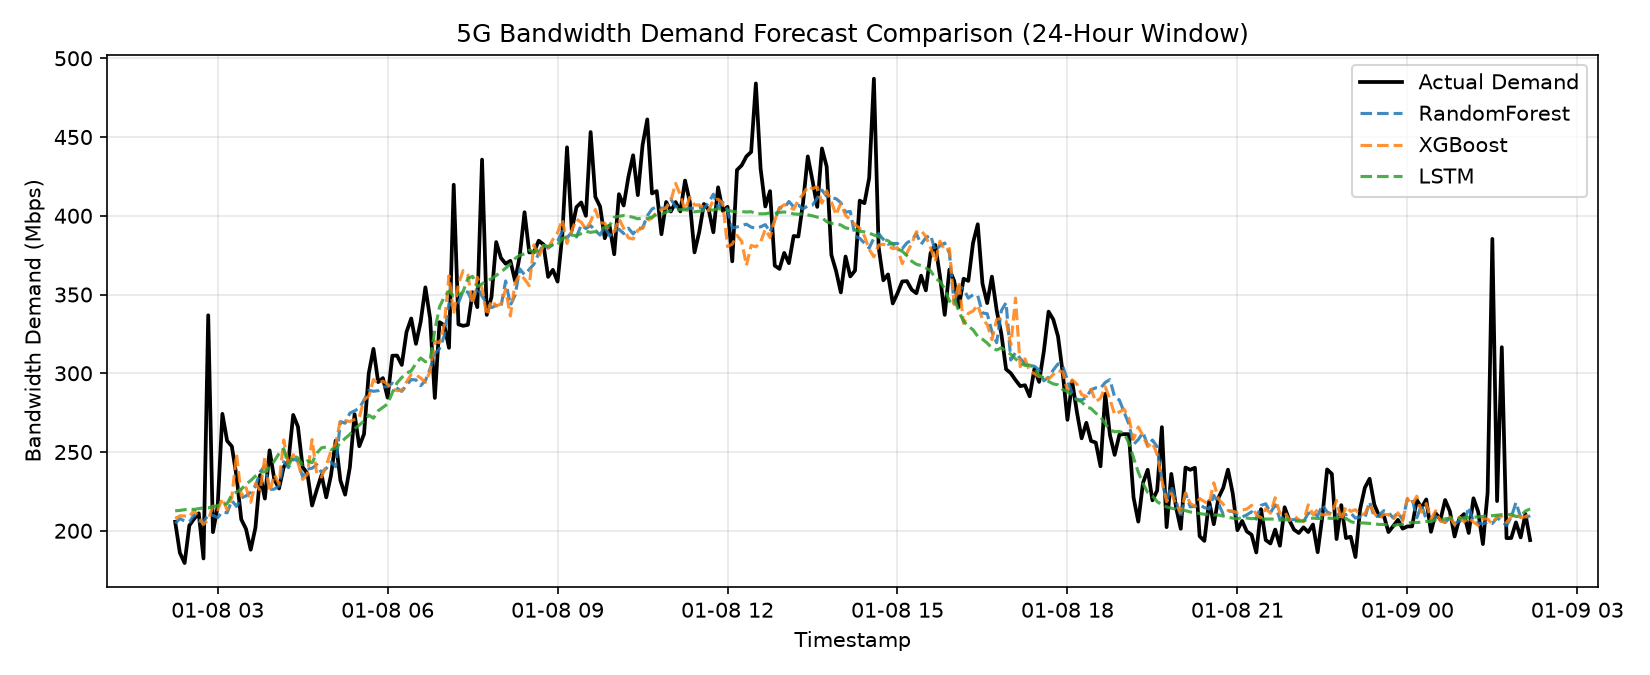

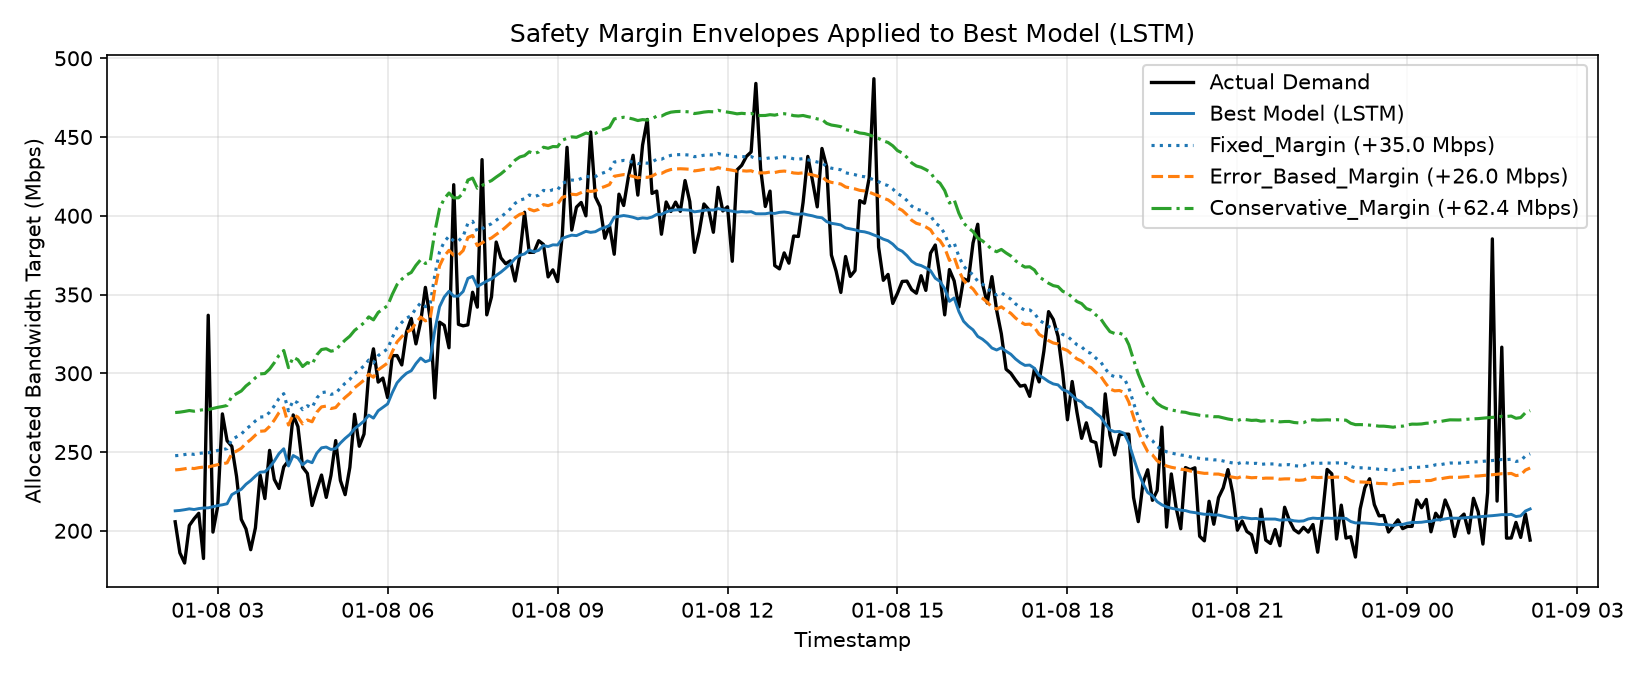

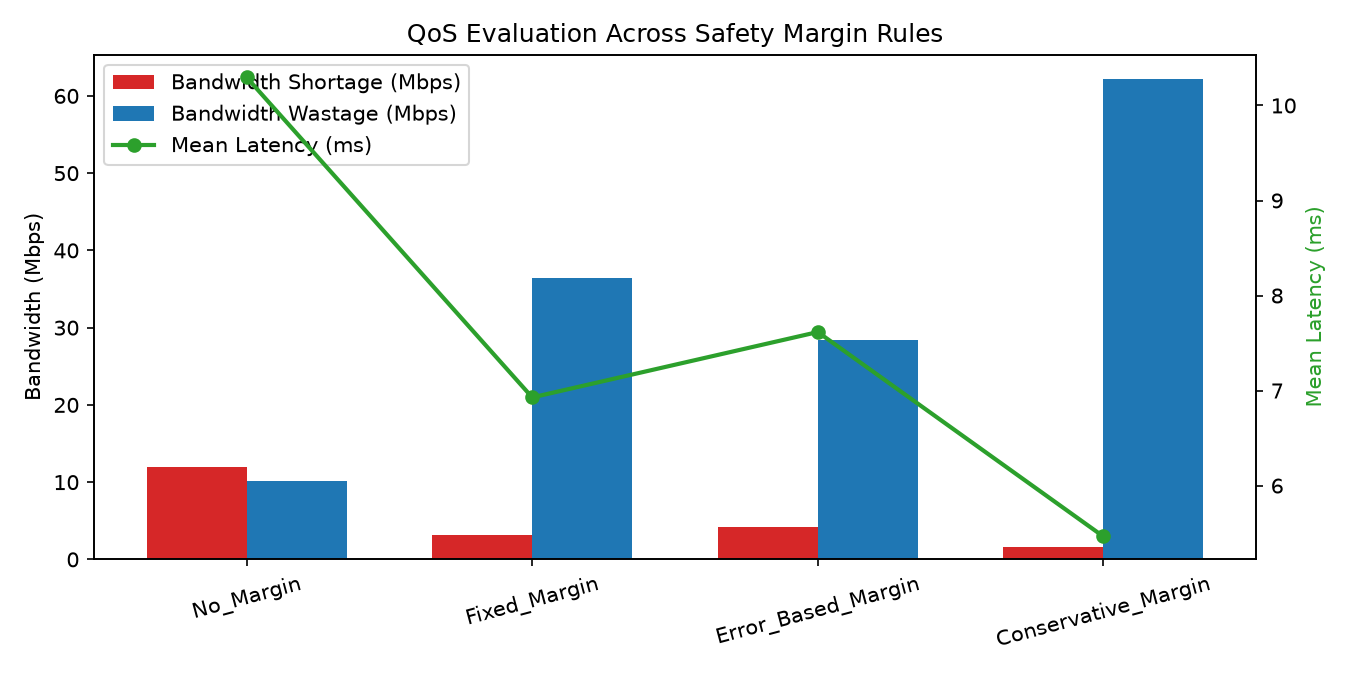

In [7]:
# Cell 7: Generate Comparison Graphs & Display Saved Figures
from IPython.display import Image, display
from forecast_and_allocate import generate_all_figures
generate_all_figures(t_te, y_te, test_preds, best_model_name, margin_dict, qos_df)
for img_path in ['results/figures/fig1_model_forecast_comparison.png', 'results/figures/fig2_safety_margin_envelopes.png', 'results/figures/fig3_qos_margin_tradeoff.png']:
    display(Image(filename=img_path))

,model,cal_mae_mean,cal_mae_std,test_mae_mean,test_mae_std,test_r2_mean,test_r2_std
0,Baseline_LastValue,28.3480,0.0000,31.6100,0.0000,0.6794,0.0000
1,Baseline_MovingAvg,24.9780,0.0000,26.2300,0.0000,0.7820,0.0000
2,LSTM,19.5840,0.1170,21.9543,0.5482,0.8387,0.0083
3,RandomForest,20.8567,0.0346,23.2110,0.0183,0.8228,0.0007
4,XGBoost,21.5120,0.0805,23.4537,0.1168,0.8219,0.0020


,margin_rule,mean_throughput_mbps_mean,mean_latency_ms_mean,jitter_ms_mean,mean_packet_loss_pct_mean,mean_bandwidth_shortage_mbps_mean,mean_bandwidth_wastage_mbps_mean
0,Conservative_Margin,293.558,5.566,1.387,0.431,1.718,59.712
1,Error_Based_Margin,291.108,7.539,2.264,1.102,4.168,29.033
2,Fixed_Margin,291.730,7.151,2.123,0.925,3.545,33.479
3,No_Margin,281.766,10.688,3.184,4.042,13.510,8.444


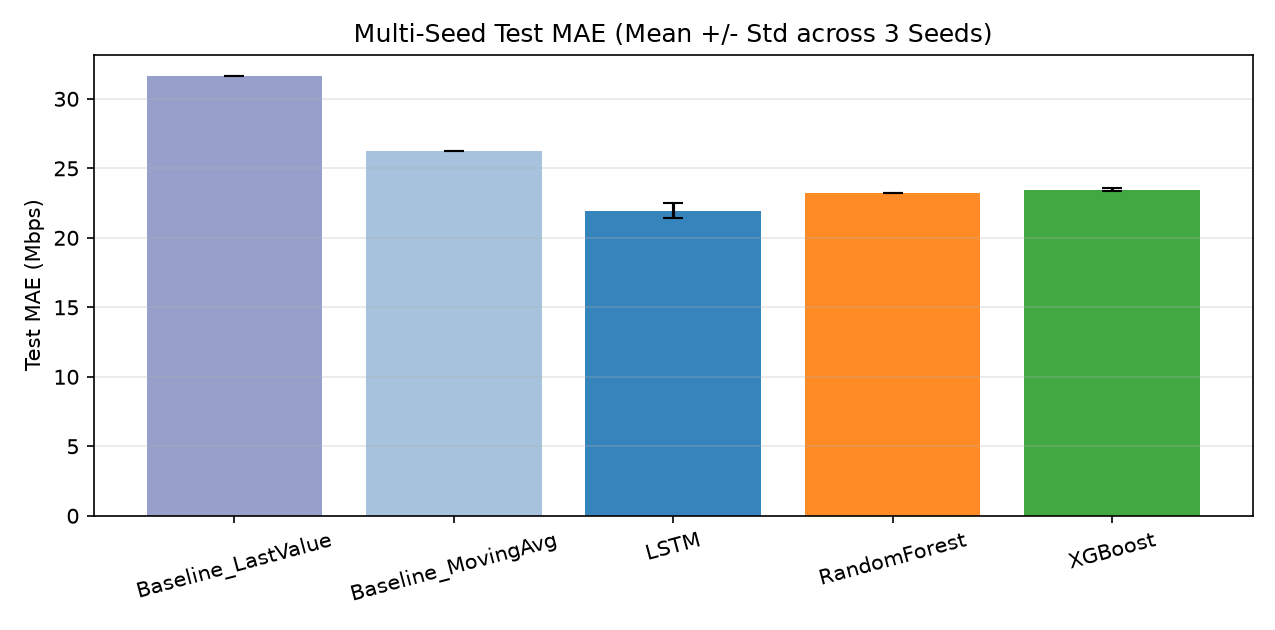

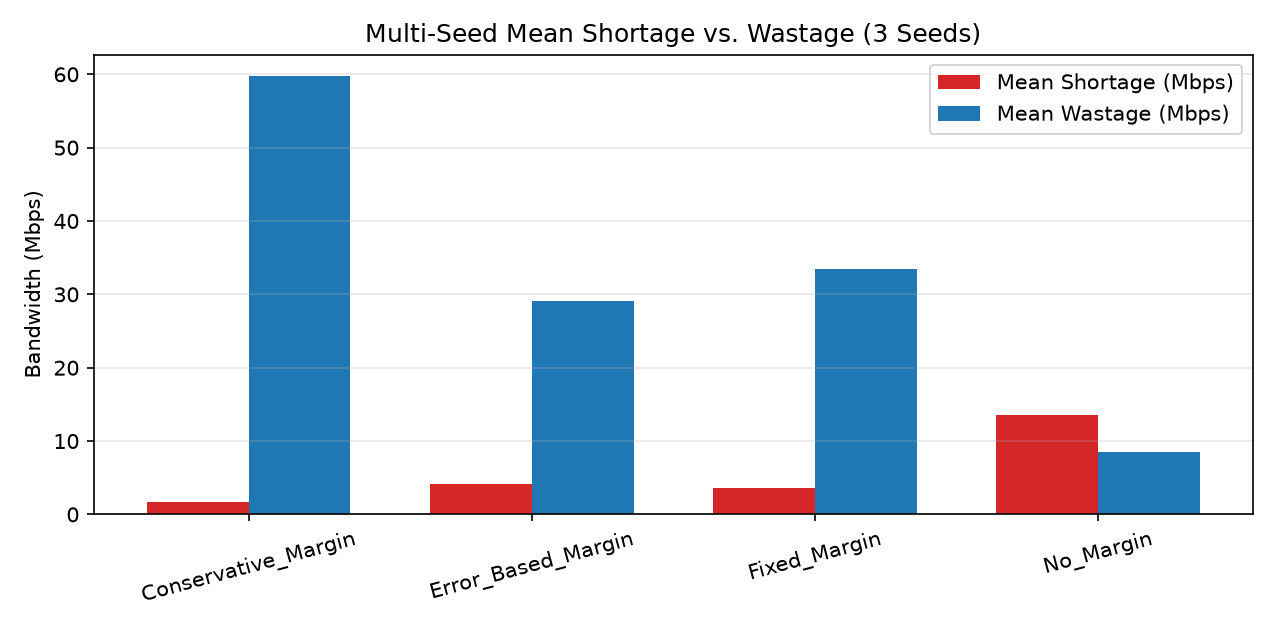

In [8]:
# Cell 8 (Optional Multi-Seed Extension): Average Forecast, Safety Margin & QoS Metrics Across All Seeds in config.yaml
from IPython.display import Image, display
from forecast_and_allocate import run_across_seeds
model_agg, margin_agg, qos_agg, _ = run_across_seeds(cfg)
display(model_agg[['model', 'cal_mae_mean', 'cal_mae_std', 'test_mae_mean', 'test_mae_std', 'test_r2_mean', 'test_r2_std']])
display(qos_agg[['margin_rule', 'mean_throughput_mbps_mean', 'mean_latency_ms_mean', 'jitter_ms_mean', 'mean_packet_loss_pct_mean', 'mean_bandwidth_shortage_mbps_mean', 'mean_bandwidth_wastage_mbps_mean']])
for p in ['results/figures/fig4_multiseed_model_mae.png', 'results/figures/fig5_multiseed_shortage_wastage.png']:
    display(Image(filename=p))